# PI3Kα (4JPS) — Step 10: Final integrated candidate review and handover

**Tryptanthrin anticancer capstone** · **Input:** `PI3Kalpha_Step9_Interaction_Analysis.zip`.

This notebook reviews all ten docked PI3Kα analogs and integrates docking rank with existing ML predictions, applicability, QED, synthetic accessibility (SA), and structural alerts. It does **not** treat docking scores as experimental potency or distance-only contacts as confirmed hydrogen bonds.

**Important:** This is a results-review and documentation notebook, not a complete docking reproduction. Preserve Step 6–9 notebooks and ZIPs separately until the final repository is assembled. Final structure/ligand preparation and redocking methodology must be consolidated and independently rerun before claiming end-to-end reproducibility.

## 1. Upload Step 9 results and verify inputs

In [1]:
%pip -q install pandas numpy matplotlib
from pathlib import Path
from google.colab import files
from IPython.display import display
import pandas as pd, numpy as np, json, zipfile, shutil, hashlib
import matplotlib.pyplot as plt

out=Path('PI3Kalpha_Step10_Final_Review');out.mkdir(exist_ok=True)
print('Upload PI3Kalpha_Step9_Interaction_Analysis.zip:')
uploaded=files.upload()
names=[k for k in uploaded if k.lower().endswith('.zip')]
if len(names)!=1: raise RuntimeError(f'Upload exactly one Step 9 ZIP, got {names}')
source=names[0]
expected={
 'PI3Kalpha_ranked_docking_with_ML_context.csv',
 'PI3Kalpha_top3_pose_quality.csv',
 'PI3Kalpha_top3_residue_contacts.csv',
 'PI3Kalpha_top3_atom_contacts.csv',
 'PI3Kalpha_step8_docking_report.json',
 'PI3Kalpha_step9_analysis_report.json'
}
with zipfile.ZipFile(source) as z:
    bad=z.testzip()
    if bad: raise RuntimeError(f'Bad ZIP member: {bad}')
    members={Path(x).name:x for x in z.namelist() if not x.endswith('/')}
    missing=expected-set(members)
    if missing: raise RuntimeError(f'Missing files: {sorted(missing)}')
    for file in expected:
        (out/file).write_bytes(z.read(members[file]))
    # Retain existing figures and top-pose visualizations where supplied
    for member in z.namelist():
        if member.endswith('/') or Path(member).suffix.lower() not in {'.png','.html','.pdb'}: continue
        destination=out/'source_visualizations'/Path(member)
        destination.parent.mkdir(parents=True,exist_ok=True)
        destination.write_bytes(z.read(member))

ranking=pd.read_csv(out/'PI3Kalpha_ranked_docking_with_ML_context.csv')
quality=pd.read_csv(out/'PI3Kalpha_top3_pose_quality.csv')
contacts=pd.read_csv(out/'PI3Kalpha_top3_residue_contacts.csv')
atoms=pd.read_csv(out/'PI3Kalpha_top3_atom_contacts.csv')
rep8=json.loads((out/'PI3Kalpha_step8_docking_report.json').read_text())
rep9=json.loads((out/'PI3Kalpha_step9_analysis_report.json').read_text())
assert len(ranking)==10 and ranking['Analog_ID'].nunique()==10, 'Expected 10 unique analogs'
assert ranking['Target'].eq('PI3Kalpha').all(), 'Wrong target in results'
assert ranking['docking_ok'].astype(str).str.lower().eq('true').all(), 'Some docking runs failed'
assert quality['Analog_ID'].nunique()==3, 'Expected exactly 3 top poses'
assert rep8['ligands_docked_successfully']==10, 'Step 8 count mismatch'
assert rep8['reference_pose_recovery_pass'] is True, 'Reference redocking did not pass'
assert set(quality['Analog_ID'])==set(ranking.nsmallest(3,'vina_best_affinity_kcal_mol')['Analog_ID'])
print('PASS: 10 unique PI3Kalpha docked ligands, 3 pose reviews, redocking RMSD:',rep8['input_redocking_RMSD_A'],'Å')
display(ranking[['Docking_rank','Analog_ID','vina_best_affinity_kcal_mol','Consensus_pIC50','Max_train_Tanimoto','QED','SA_score']])

Upload PI3Kalpha_Step9_Interaction_Analysis.zip:


Saving PI3Kalpha_Step9_Interaction_Analysis.zip to PI3Kalpha_Step9_Interaction_Analysis.zip
PASS: 10 unique PI3Kalpha docked ligands, 3 pose reviews, redocking RMSD: 0.6039 Å


,Docking_rank,Analog_ID,vina_best_affinity_kcal_mol,Consensus_pIC50,Max_train_Tanimoto,QED,SA_score
0,1,TRY_6db5e7a7802259ab,-10.290,6.29428,0.409836,0.540506,2.488290
1,2,TRY_c88335488290afb4,-10.261,6.25409,0.403226,0.556121,2.444439
2,3,TRY_c6b27d68ce6ec718,-10.175,6.36582,0.413333,0.560274,2.506605
3,4,TRY_6bf367653fed7969,-9.473,6.26524,0.402778,0.560199,2.569880
4,5,TRY_c2155e898021da1c,-9.383,6.44444,0.400000,0.560199,2.508959
5,6,TRY_bafc3535a3d34b71,-9.288,6.22232,0.417910,0.540488,2.411619
6,7,TRY_40b0c0e6de99494a,-9.280,6.33990,0.432836,0.540488,2.422261
7,8,TRY_f751442f427b1d4d,-9.170,6.30231,0.400000,0.560199,2.587839
8,9,TRY_e514ff1b3f600530,-8.910,6.22360,0.451613,0.540488,2.458244
9,10,TRY_783966fbcbaa4f5c,-8.716,6.21648,0.403226,0.539044,2.577449


## 2. Transparent evidence-based ranking

Keep **docking rank** as the reproducible primary ordering; show ML/QED/SA/alerts and caution flags alongside. Do not add arbitrary weighted composite scores or claim that −10.29 vs −10.26 kcal/mol is a meaningful affinity difference.

In [2]:
r=ranking.sort_values('vina_best_affinity_kcal_mol',ascending=True).copy().reset_index(drop=True)
r['Docking_rank_verified']=np.arange(1,11)
r['Docking_score_interpretation']='relative Vina score only, same receptor/setting'
r['ML_applicability_caution']=np.where(r['Max_train_Tanimoto']<0.5,
 'LOW similarity to training data (<0.50); ML activity uncertain',
 'Review applicability; similarity alone is not a validation guarantee')
r['Model_agreement_caution']=np.where(r['Model_disagreement_abs']>=0.3,
 'RF/XGB predictions differ by >=0.30 pIC50','')
for flag in ['PAINS_flag','Brenk_flag']:
    r[flag]=r[flag].astype(str).str.strip().str.lower().isin({'true','1','yes'})
r['Structural_alert_caution']=np.where(r['PAINS_flag']|r['Brenk_flag'],
 'Review PAINS/Brenk alerts','No PAINS/Brenk flag in supplied table')
r['Decision_status']='Computationally prioritised for follow-up; not validated inhibition'
r.to_csv(out/'PI3Kalpha_final_candidate_ranking.csv',index=False)
print('Saved transparent 10-compound final ranking')
display(r[['Docking_rank_verified','Analog_ID','vina_best_affinity_kcal_mol','Consensus_pIC50','Max_train_Tanimoto','QED','SA_score','Model_agreement_caution']])

Saved transparent 10-compound final ranking


,Docking_rank_verified,Analog_ID,vina_best_affinity_kcal_mol,Consensus_pIC50,Max_train_Tanimoto,QED,SA_score,Model_agreement_caution
0,1,TRY_6db5e7a7802259ab,-10.290,6.29428,0.409836,0.540506,2.488290,
1,2,TRY_c88335488290afb4,-10.261,6.25409,0.403226,0.556121,2.444439,
2,3,TRY_c6b27d68ce6ec718,-10.175,6.36582,0.413333,0.560274,2.506605,
3,4,TRY_6bf367653fed7969,-9.473,6.26524,0.402778,0.560199,2.569880,
4,5,TRY_c2155e898021da1c,-9.383,6.44444,0.400000,0.560199,2.508959,
5,6,TRY_bafc3535a3d34b71,-9.288,6.22232,0.417910,0.540488,2.411619,
6,7,TRY_40b0c0e6de99494a,-9.280,6.33990,0.432836,0.540488,2.422261,
7,8,TRY_f751442f427b1d4d,-9.170,6.30231,0.400000,0.560199,2.587839,RF/XGB predictions differ by >=0.30 pIC50
8,9,TRY_e514ff1b3f600530,-8.910,6.22360,0.451613,0.540488,2.458244,RF/XGB predictions differ by >=0.30 pIC50
9,10,TRY_783966fbcbaa4f5c,-8.716,6.21648,0.403226,0.539044,2.577449,


## 3. Top-three docking contact review

These are heavy-atom **proximity** metrics, not chemical bond assignments. No atom-pair overlap below 2 Å was recorded by Step 9, but detailed protonation, orientations, and stereochemistry require visual inspection.

In [5]:

# Merge top-three docking results with pose-quality metrics.
# Keep the original Vina score from the ranking table.

quality_metrics = quality.drop(
    columns=["vina_best_affinity_kcal_mol"],
    errors="ignore"
)

top3 = r.head(3).merge(
    quality_metrics,
    on="Analog_ID",
    how="left",
    validate="one_to_one"
)

required_metrics = [
    "residues_within_4A",
    "atom_pairs_within_4A",
    "min_interatomic_distance_A"
]

assert not top3[required_metrics].isna().any().any(), (
    "Missing top-three contact metrics"
)

summary_cols = [
    "Docking_rank_verified",
    "Analog_ID",
    "vina_best_affinity_kcal_mol",
    "Consensus_pIC50",
    "Pred_RF_pIC50",
    "Pred_XGB_pIC50",
    "Max_train_Tanimoto",
    "QED",
    "SA_score",
    "residues_within_4A",
    "atom_pairs_within_4A",
    "atom_pairs_below_2A",
    "min_interatomic_distance_A",
    "ML_applicability_caution"
]

top3[summary_cols].to_csv(
    out / "PI3Kalpha_top3_integrated_summary.csv",
    index=False
)

display(top3[summary_cols])

print("Top 3 proximity contacts:")

for analog in top3["Analog_ID"]:
    c = contacts[contacts["Analog_ID"] == analog]

    nearby = c.sort_values("min_distance_A").head(6)

    print(
        analog, ":",
        ", ".join(nearby["residue"].astype(str))
    )

print("PASS: Top-three integrated summary generated")


,Docking_rank_verified,Analog_ID,vina_best_affinity_kcal_mol,Consensus_pIC50,Pred_RF_pIC50,Pred_XGB_pIC50,Max_train_Tanimoto,QED,SA_score,residues_within_4A,atom_pairs_within_4A,atom_pairs_below_2A,min_interatomic_distance_A,ML_applicability_caution
0,1,TRY_6db5e7a7802259ab,-10.290,6.29428,6.36380,6.22475,0.409836,0.540506,2.488290,15,62,0,3.226,LOW similarity to training data (<0.50); ML ac...
1,2,TRY_c88335488290afb4,-10.261,6.25409,6.28987,6.21832,0.403226,0.556121,2.444439,13,60,0,2.985,LOW similarity to training data (<0.50); ML ac...
2,3,TRY_c6b27d68ce6ec718,-10.175,6.36582,6.30865,6.42299,0.413333,0.560274,2.506605,14,59,0,2.745,LOW similarity to training data (<0.50); ML ac...


Top 3 proximity contacts:
TRY_6db5e7a7802259ab : VAL851, TYR836, SER854, TRP780, ASP933, ASN853
TRY_c88335488290afb4 : TYR836, ASP933, VAL851, SER854, ASP810, TRP780
TRY_c6b27d68ce6ec718 : VAL851, SER854, MET772, ILE848, MET922, TRP780
PASS: Top-three integrated summary generated


## 4. Results plot

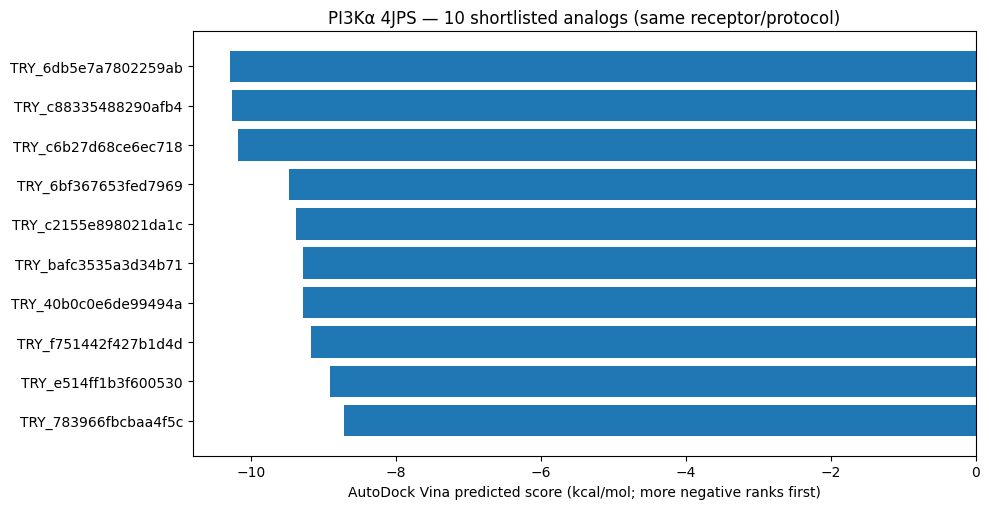

In [6]:
fig,ax=plt.subplots(figsize=(10,5.2))
ax.barh(r['Analog_ID'][::-1],r['vina_best_affinity_kcal_mol'][::-1])
ax.set_xlabel('AutoDock Vina predicted score (kcal/mol; more negative ranks first)')
ax.set_title('PI3Kα 4JPS — 10 shortlisted analogs (same receptor/protocol)')
fig.tight_layout()
fig.savefig(out/'PI3Kalpha_final_docking_ranking.png',dpi=180,bbox_inches='tight')
plt.show()

## 5. Generate final report, methods and reproducibility manifest

In [7]:
def fmt(x,nd=3): return f'{float(x):.{nd}f}'
rows=['# PI3Kα (4JPS) — Integrated docking results', '',
      '**Target:** PIK3CA · **Structure:** 4JPS · **Reference ligand:** alpelisib (1LT)', '',
      '## Reference redocking and protocol', '',
      f"- Symmetry-aware crystallographic-coordinate heavy-atom RMSD: **{fmt(rep8['input_redocking_RMSD_A'],4)} Å**",
      f"- AutoDock Vina {rep8['vina_version']}, exhaustiveness {rep8['exhaustiveness']}, num_modes {rep8['num_modes']}, seed {rep8['seed']}",
      f"- Grid center (Å): {rep8['center_A']}; grid dimensions (Å): {rep8['size_A']}",
      f"- Receptor preparation limitation: {rep8['receptor_preparation_caveat']}", '',
      '## Ten-analogue results', '',
      '| Rank | Analog_ID | Vina score (kcal/mol) | ML consensus pIC50 | Max train Tanimoto |',
      '|---:|---|---:|---:|---:|']
for row in r.itertuples():
    rows.append(f'| {row.Docking_rank_verified} | `{row.Analog_ID}` | {fmt(row.vina_best_affinity_kcal_mol)} | {fmt(row.Consensus_pIC50,2)} | {fmt(row.Max_train_Tanimoto)} |')
rows.extend(['','## Top-three pose analysis',''])
for row in top3.itertuples():
    rows.append(f'- **{row.Analog_ID}**: {int(row.residues_within_4A)} residues and {int(row.atom_pairs_within_4A)} heavy-atom pairs within 4 Å; minimum distance {fmt(row.min_interatomic_distance_A)} Å; pairs below 2 Å: {int(row.atom_pairs_below_2A)}.')
rows.extend(['','## Scientific interpretation and limitations','',
  '- Docking scores are computational rankings for this receptor only, not measured affinity or confirmed cancer inhibition.',
  '- Contact counts and polar atom distances do not establish hydrogen bonds; donor/acceptor chemistry and angles need separate validation.',
  '- The top-three compounds have limited similarity (~0.40–0.41) to training structures; ML extrapolation remains uncertain.',
  '- QED, SA, PAINS and Brenk information is inherited from the upstream screening table and does not confirm drug safety or synthesizability.',
  '- Ten distant problematic receptor residues were excluded during preparation; document this and the engineered receptor mutations.',
  '- Small differences between Vina scores should not be considered significant without further uncertainty analysis.', '',
  '## Output files','',
  '- `PI3Kalpha_final_candidate_ranking.csv` — all ten docked analogues with ML/QED/SA and caution flags.',
  '- `PI3Kalpha_top3_integrated_summary.csv` — three top poses, contact counts and minima.',
  '- `PI3Kalpha_final_docking_ranking.png` — docking score figure.',
  '- `source_visualizations/` — Step 9 pose files, HTML views and figures.',
  '- Earlier Step 6–9 artifacts are needed for more complete provenance and end-to-end reproduction.', ''])
(out/'PI3Kalpha_Final_Results_Report.md').write_text('\n'.join(rows),encoding='utf-8')
manifest={'target':'PI3Kalpha','pdb_id':'4JPS','reference_ligand':'1LT','source_zip':source,'source_sha256':hashlib.sha256(Path(source).read_bytes()).hexdigest(),'source_step8_report':rep8,'source_step9_report':rep9,'n_docked_analogs':len(r),'n_pose_reviewed':len(top3),'ranking_rule':'ascending Vina score; no artificial composite score','end_to_end_reproduction_tested':False}
(out/'PI3Kalpha_final_provenance.json').write_text(json.dumps(manifest,indent=2)+'\n')
print('Report and provenance saved. Keep original Step 6–9 artifacts for repository submission.')

Report and provenance saved. Keep original Step 6–9 artifacts for repository submission.


## 6. Download Step 10 final review archive

In [8]:
archive=shutil.make_archive('PI3Kalpha_Step10_Final_Review','zip',out)
print('Saved',archive)
files.download(archive)
print('Save this executed notebook too. Next: assemble one clean PI3Kalpha GitHub folder like EGFR.')

Saved /content/PI3Kalpha_Step10_Final_Review.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Save this executed notebook too. Next: assemble one clean PI3Kalpha GitHub folder like EGFR.
